In [ ]:
import os, sys

# Point Spark to Java 17, Hadoop/winutils and the Python in this environment
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"
os.environ["HADOOP_HOME"] = "C:/Hadoop/hadoop-3.3.1"
os.environ["PATH"] += ";C:/Hadoop/hadoop-3.3.1/bin"
os.environ["PYSPARK_HADOOP_VERSION"] = "without"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

In [ ]:
from cassandra.cluster import Cluster
cluster = Cluster(["127.0.0.1"], port=9042)
# Connect to Cassandra running in Docker

session = cluster.connect()

# Create a keyspace and a small test table
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS test_keyspace
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")
session.execute("""
    CREATE TABLE IF NOT EXISTS test_keyspace.test_table (id int PRIMARY KEY, name text);
""")
print("Cassandra OK")



In [ ]:
from pyspark.sql import SparkSession

# Start Spark with the Spark-Cassandra connector (downloaded automatically the first time)
spark = (SparkSession.builder
         .appName("CassandraTest")
         .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
         .config("spark.cassandra.connection.host", "127.0.0.1")
         .config("spark.cassandra.connection.port", "9042")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
print("Spark OK")

In [ ]:
# Write two rows to Cassandra via Spark
df = spark.createDataFrame([(1, "Maryan"), (2, "Test")], ["id", "name"])
(df.write.format("org.apache.spark.sql.cassandra")
   .options(table="test_table", keyspace="test_keyspace")
   .mode("append").save())

# Read them back
(spark.read.format("org.apache.spark.sql.cassandra")
   .options(table="test_table", keyspace="test_keyspace")
   .load().show())

In [ ]:
# Keyspace and table for the cross-border flows.
# Partition key (connection, direction) groups each line and direction together,
# and time sorts the hourly values within each group.
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.flows (
        connection text,
        direction text,
        time timestamp,
        from_area text,
        to_area text,
        flow_mw double,
        PRIMARY KEY ((connection, direction), time)
    );
""")
print("Table ready")

In [ ]:
# Spark needs times without timezone info - they are already in UTC
flows_out = flows.copy()
flows_out["time"] = flows_out["time"].dt.tz_localize(None)
flows_out = flows_out.dropna(subset=["flow_mw"])

# Throttle the writes so the local single-node Cassandra in Docker keeps up
spark.conf.unset("spark.cassandra.output.batch.size.rows")
spark.conf.set("spark.cassandra.output.concurrent.writes", "1")
spark.conf.set("spark.cassandra.output.throughputMBPerSec", "1")

# One partition = one writer at a time
sdf = spark.createDataFrame(flows_out).repartition(1)
(sdf.write.format("org.apache.spark.sql.cassandra")
    .options(table="flows", keyspace="ind320")
    .mode("append").save())
print("Rows written:", sdf.count())

In [ ]:
from pyspark.sql import functions as F

# Read gently from the local single-node Cassandra
spark.conf.set("spark.cassandra.concurrent.reads", "1")
spark.conf.set("spark.cassandra.input.fetch.sizeInRows", "500")

# Read the flows from Cassandra once, keep only the columns we need,
# and cache them in Spark so the plots below don't query Cassandra again
flows_spark = (spark.read.format("org.apache.spark.sql.cassandra")
               .options(table="flows", keyspace="ind320")
               .load()
               .select("connection", "direction", "time", "flow_mw")
               .cache())

print("Rows read from Cassandra:", flows_spark.count())
flows_spark.show(5)

In [ ]:
# Choose connection and year
#In 2025, about 91 % of the energy on the NO2–Germany connection (NordLink) flowed out of Norway.
import matplotlib.pyplot as plt
conn = "NO_2-DE_LU"
year = 2025

# Spark sums the hourly MW values per direction (MW over one hour = MWh) -> TWh
pie_df = (flows_spark
          .filter((F.col("connection") == conn) & (F.year("time") == year))
          .groupBy("direction")
          .agg((F.sum("flow_mw") / 1e6).alias("TWh"))
          .toPandas())

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(pie_df["TWh"], labels=[f"{d} ({v:.2f} TWh)" for d, v in zip(pie_df["direction"], pie_df["TWh"])],
       autopct="%1.0f%%", startangle=90)
ax.set_title(f"{conn}, {year}: export out of vs import into Norway")
plt.show()

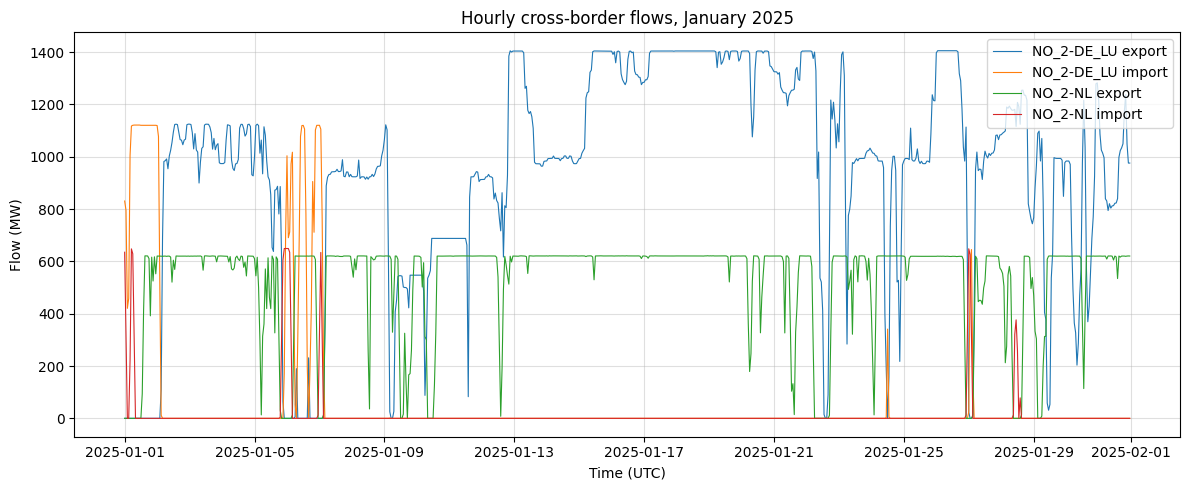

In [22]:
# Choose year and which connections to show
year = 2025
chosen = ["NO_2-DE_LU", "NO_2-NL"]

# Filter with Spark: chosen connections, January of the chosen year
jan = (flows_spark
       .filter(F.col("connection").isin(chosen) &
               (F.year("time") == year) & (F.month("time") == 1))
       .toPandas()
       .sort_values("time"))

# One line per connection and direction
fig, ax = plt.subplots(figsize=(12, 5))
for (c, d), group in jan.groupby(["connection", "direction"]):
    ax.plot(group["time"], group["flow_mw"], linewidth=0.8, label=f"{c} {d}")

ax.set_title(f"Hourly cross-border flows, January {year}")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Flow (MW)")
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [23]:
import toml
import pandas as pd
from pymongo import MongoClient

# Aggregate the hourly flows to daily energy (MWh) with Spark,
# so the Streamlit app gets a small, fast dataset
daily = (flows_spark
         .groupBy("connection", "direction", F.to_date("time").alias("date"))
         .agg(F.sum("flow_mw").alias("energy_mwh"))
         .toPandas())

# MongoDB needs full datetimes; year and month make filtering in Streamlit easy
daily["date"] = pd.to_datetime(daily["date"])
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month

# Connect to MongoDB Atlas and replace any old data in the collection
secrets = toml.load("../.streamlit/secrets.toml")
client = MongoClient(secrets["mongo"]["uri"])
collection = client["ind320"]["flows_daily"]
collection.delete_many({})
collection.insert_many(daily.to_dict("records"))

print("Documents in MongoDB:", collection.count_documents({}))

Documents in MongoDB: 13176


In [ ]:
import toml
from pymongo import MongoClient

# Read the connection string from secrets.toml (kept out of GitHub)
secrets = toml.load("../.streamlit/secrets.toml")
client = MongoClient(secrets["mongo"]["uri"])

# Insert and read back a test document
db = client["ind320"]
db["test"].insert_one({"navn": "test", "verdi": 1})
print(db["test"].find_one({"navn": "test"}))

In [ ]:
## Magasinstatistikk fra NVE API 
import requests
import pandas as pd

# Base URL for NVE's Magasinstatistikk API (no API key needed)
BASE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Fetch all public reservoir statistics
response = requests.get(f"{BASE_URL}/HentOffentligData", timeout=30)
response.raise_for_status()
df_mag = pd.DataFrame(response.json())

# Convert the date column to proper datetime
df_mag["dato_Id"] = pd.to_datetime(df_mag["dato_Id"])

df_mag.head()

In [ ]:
# Fetch the list of areas covered by the API
response = requests.get(f"{BASE_URL}/HentOmråder", timeout=30)
response.raise_for_status()
areas = response.json()

# The API returns a list - handle both possible structures
if isinstance(areas, list) and len(areas) > 0 and "omrnr" not in areas[0]:
    # A list containing one dict with keys like land/elspot/vassdrag
    areas = areas[0]
    for area_type, area_list in areas.items():
        print(area_type, [a["omrnr"] for a in area_list])
else:
    # A flat list of areas - group them by area type
    df_areas = pd.DataFrame(areas)
    print(df_areas.groupby("omrType")["omrnr"].apply(list))

# Area types present in the reservoir data
print(df_mag["omrType"].unique())

## Magasinstatistikk from the NVE API

Reservoir data are now fetched directly from NVE's open Magasinstatistikk API
instead of the CSV file from part 1.

The API covers three area types: the whole of Norway (NO, area 0), the five
price areas NO1–NO5 (EL, areas 1–5) and four river system regions (VASS, areas 1–4).
Data are weekly, with filling level and capacity for each area.

In [ ]:
# Show full names and descriptions for all areas
rows = []
for area_type, area_list in areas.items():
    for a in area_list:
            rows.append({"type": area_type, "nr": a["omrnr"],
                     "navn": a["navn"], "beskrivelse": a["beskrivelse"]})
pd.DataFrame(rows)

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

# Same English column names as in part 1, so the plotting code can be reused
rename_map = {
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "filling_degree",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "filling_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "filling_degree_prev_week",
    "endring_fyllingsgrad": "filling_degree_change",
}
df = df_mag.rename(columns=rename_map)
df["date"] = pd.to_datetime(df["date"])

# National total for Norway, sorted by date (same as in part 1)
norway = df[df["area_type"] == "NO"].sort_values("date").reset_index(drop=True)
measure_cols = norway.select_dtypes("number").columns.tolist()

print("Date range:", norway["date"].min().date(), "to", norway["date"].max().date())
display(norway.head())

In [ ]:
# One subplot per measurement, with a shared time axis
fig, axes = plt.subplots(len(measure_cols), 1, figsize=(12, 2.6 * len(measure_cols)), sharex=True)

for ax, col in zip(axes, measure_cols):
    ax.plot(norway["date"], norway[col], linewidth=0.8)
    ax.set_title(col)
    ax.grid(True, alpha=0.4)

axes[-1].set_xlabel("Date")
fig.suptitle("Norwegian reservoirs (national total, weekly) - from API")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [ ]:
# Min-max normalisation: (value - min) / (max - min) gives 0-1 for each column
values = norway[measure_cols]
spread = (values.max() - values.min()).replace(0, 1)  # avoid division by zero
normalised = (values - values.min()) / spread

fig, ax = plt.subplots(figsize=(12, 5))
for col in measure_cols:
    ax.plot(norway["date"], normalised[col], linewidth=0.8, label=col)

ax.set_title("All columns together (min-max normalised) - from API")
ax.set_xlabel("Date")
ax.set_ylabel("Normalised value (0-1)")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# Same data for one year only, where the seasonal variation is easier to see
one_year = norway[norway["date"].dt.year == 2023]
norm_year = (one_year[measure_cols] - values.min()) / spread

fig, ax = plt.subplots(figsize=(12, 4))
for col in measure_cols:
    ax.plot(one_year["date"], norm_year[col], marker="o", markersize=3, label=col)
ax.set_title("All columns together, 2023 (normalised) - from API")
ax.set_xlabel("Date")
ax.set_ylabel("Normalised value (0-1)")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:
## Cross-border flows from ENTSO-E
import toml
import pandas as pd
from entsoe import EntsoePandasClient

# Read the ENTSO-E token from secrets.toml (kept out of GitHub)
secrets = toml.load("../.streamlit/secrets.toml")
client = EntsoePandasClient(api_key=secrets["entsoe"]["token"])

# Test: physical flow from NO2 to Denmark (DK1) for one week
start = pd.Timestamp("2025-01-01", tz="Europe/Oslo")
end = pd.Timestamp("2025-01-08", tz="Europe/Oslo")
flow = client.query_crossborder_flows("NO_2", "DK_1", start=start, end=end)

flow.head(10)

In [ ]:
# All cross-border connections between Norwegian price areas and neighbouring countries
connections = [
    ("NO_1", "SE_3"),
    ("NO_2", "DK_1"),
    ("NO_2", "NL"),
    ("NO_2", "DE_LU"),
    ("NO_2", "GB"),
    ("NO_3", "SE_2"),
    ("NO_4", "SE_1"),
    ("NO_4", "SE_2"),
    ("NO_4", "FI"),
]

# The last two full years
start = pd.Timestamp("2024-01-01", tz="Europe/Oslo")
end = pd.Timestamp("2026-01-01", tz="Europe/Oslo")

frames = []
for no_area, foreign in connections:
    # Fetch both directions: out of Norway (export) and into Norway (import)
    for area_from, area_to, direction in [(no_area, foreign, "export"),
                                          (foreign, no_area, "import")]:
        try:
            s = client.query_crossborder_flows(area_from, area_to, start=start, end=end)
            # Some periods have 15-minute resolution - average to hourly values
            s = s.resample("h").mean()
            part = s.rename("flow_mw").reset_index().rename(columns={"index": "time"})
            part["time"] = part["time"].dt.tz_convert("UTC")  # store all times in UTC
            part["connection"] = f"{no_area}-{foreign}"
            part["from_area"] = area_from
            part["to_area"] = area_to
            part["direction"] = direction
            frames.append(part)
            print(f"OK: {area_from} -> {area_to} ({len(part)} rows)")
        except Exception as e:
            print(f"Failed: {area_from} -> {area_to}: {e}")

flows = pd.concat(frames, ignore_index=True)
flows.head()

In [ ]:
# Save a local backup so the slow API download doesn't have to be repeated
flows.to_pickle("flows_backup.pkl")

# To load it again later (instead of re-downloading):
# flows = pd.read_pickle("flows_backup.pkl")